---
title: "Chapter 20: Survival analysis"
---

::: {.callout-lo}
## Learning outcomes {.unnumbered}

By the end of this chapter, you should be able to:

- Recognize right-censored outcomes and explain what information they contain.
- Explain why ordinary regression and snapshot classification do not directly answer a censored time-to-event question.
- Interpret a Kaplan–Meier survival curve and explain how censored observations contribute to it.
- Fit a Cox proportional hazards model and interpret coefficients as hazard ratios.
- Distinguish predictions from signup from predictions of remaining time for an existing customer.
- Evaluate survival predictions on held-out data and recognize important assumptions and limitations.
:::

**Imports**

This chapter uses `lifelines` alongside our familiar Python tools. If needed, install it in the environment used to run this notebook:

```bash
python -m pip install lifelines
```

In [1]:
#| code-fold: true
#| code-summary: "Show imports and setup"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.plotting import add_at_risk_counts
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_DIR = Path("data") if Path("data").is_dir() else Path("book") / "data"
plt.rcParams["font.size"] = 12

Matplotlib is building the font cache; this may take a moment.


## Why we need survival analysis

Imagine you work for a subscription-based telecom company. Your team wants to anticipate when customers might leave so that it can plan retention efforts. A prediction of when a customer will leave could help decide when to contact them, although it would not tell us whether a particular promotion would persuade them to stay.

You already know classification and regression. We could classify customers as likely to churn, or use regression to predict the number of months until they leave. Before choosing a model, though, we need to ask: **what target values do we actually have?**

Suppose our records contain these three customers. We measure time from each customer's signup.

| Customer | Observed duration | Churn observed? | What we know about time to churn |
|---|---:|---|---|
| A | 4 months | Yes | They churned at month 4. |
| B | 4 months | No | They stayed beyond month 4; their final duration is unknown. |
| C | 18 months | No | They stayed beyond month 18; their final duration is unknown. |

A and B have the same observed duration, but very different outcomes. For A, four months is a completed subscription. For B, it is only the duration observed so far.

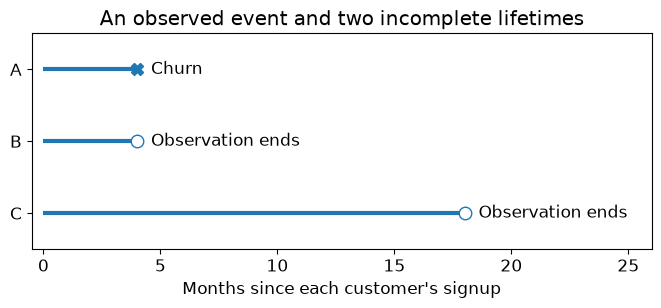

In [2]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for y, (customer, duration, observed) in enumerate(
    [("A", 4, True), ("B", 4, False), ("C", 18, False)]
):
    ax.hlines(y, 0, duration, color="tab:blue", linewidth=3)
    ax.plot(duration, y, "X" if observed else "o", color="tab:blue",
            markerfacecolor="tab:blue" if observed else "white", markersize=9)
    ax.text(duration + 0.6, y, "Churn" if observed else "Observation ends", va="center")
ax.set(yticks=[0, 1, 2], yticklabels=["A", "B", "C"],
       xlabel="Months since each customer's signup", xlim=(-0.5, 26), ylim=(-0.5, 2.5))
ax.invert_yaxis()
ax.set_title("An observed event and two incomplete lifetimes")
plt.show()

The open circles mark the end of observation, not churn. These timelines align customers by time since signup; they need not have joined on the same calendar date.

B and C are **right-censored**: we stopped observing them before observing the event. Their durations give us lower bounds on their time to churn. Censoring does not mean that a customer will never leave, and it does not erase what we already know about their subscription.

This is the gap in our current toolbox. An ordinary regressor expects an exact numerical target for every training example. Here, some targets are exact event times and others are bounds. We need an approach that can learn from both.

Although the name **survival analysis** comes from studying lifetimes, its methods apply to time until many kinds of events: equipment failure, finding a job, or leaving a subscription service. We must define both the event and the time origin. Here they are churn and signup, respectively.

### What about classification?

Suppose we collect a snapshot of customer records, with a `Churn` column indicating whether churn has been observed. A classifier trained on this column learns to distinguish customers recorded as having churned from those recorded as active. That is different from predicting their eventual subscription length. In particular, an active customer observed for two months has had much less opportunity to churn than one observed for two years.

Classification can still answer a useful question such as “Will this customer churn within six months of signup?” But we need labels for that specific horizon. A customer who churned at month 4 has a known positive label; a customer still active at month 8 has a known negative label. For a customer whose observation ends at month 2 without churn, the six-month label is unknown. Labelling that customer negative would be a mistake.

To answer questions about timing, we need to retain how long each customer was observed and whether churn occurred. Let’s see what happens when we try to use our familiar regression workflow on data with this structure.

### A customer churn example

To explore this problem, we will use the [Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). For this teaching example, we interpret `tenure` as the number of months from signup to churn or the end of observation, and `Churn` as the indicator that churn was observed.

::: {.callout-note title="What this dataset can establish"}
The table is a snapshot, rather than a documented longitudinal record of every customer's history. Our interpretation of duration, event status, and follow-up is a teaching assumption. Before using these methods operationally, we would verify how customers were sampled, how churn and follow-up were recorded, and which features were available at prediction time.

In particular, current contract and billing information need not be the information available at signup. We will use these attributes to demonstrate the models, but the resulting predictions are not a validated deployment workflow.
:::

As usual, we reserve a test set before fitting models or preprocessing.

In [3]:
df = pd.read_csv(DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
train_df, test_df = train_test_split(df, test_size=0.25, random_state=123)
train_df = train_df.copy()
test_df = test_df.copy()
display(train_df[["tenure", "Churn", "Contract", "MonthlyCharges"]].head())
display(train_df["Churn"].value_counts())

,tenure,Churn,Contract,MonthlyCharges
6464,50,No,Month-to-month,70.35
5707,2,No,Month-to-month,45.55
3442,29,No,Month-to-month,98.80
3932,2,Yes,Month-to-month,78.55
6124,57,No,One year,59.30


Churn
No     3912
Yes    1370
Name: count, dtype: int64

### Two tempting shortcuts

The `tenure` column looks like a numerical regression target. But its meaning depends on `Churn`: for some rows it is a completed subscription length, while for others it is follow-up so far. Could we still adapt our usual regression workflow? Consider these two choices before running any code.

**Use only customers who churned.** We have their completed subscription lengths, so we could discard the other rows and fit a regressor. But the retained customers are selected because their event was observed during follow-up. Customers with longer event times are more likely to remain censored. We would discard their evidence of longer survival and generally bias the estimated lifetime downward under the usual independent-censoring setup.

**Treat every observed tenure as a completed lifetime.** This keeps all the rows, but treats active customers as if they churned when observation ended. For each censored customer, the supplied target is shorter than their eventual subscription. We would be learning observed follow-up time rather than the time to churn.

Neither changing regressors nor tuning hyperparameters repairs the meaning of these targets. We can illustrate the two shortcuts with the familiar `Ridge` model. We use a small set of features to keep attention on the target.

In [4]:
numeric_features = ["MonthlyCharges"]
categorical_features = ["Contract", "InternetService", "PaymentMethod"]
feature_columns = numeric_features + categorical_features + ["SeniorCitizen"]

def make_regression_pipeline():
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features),
        ("binary", "passthrough", ["SeniorCitizen"]),
    ])
    return make_pipeline(preprocessing, Ridge())

churned = train_df["Churn"].eq("Yes")
observed_events_only = make_regression_pipeline()
observed_events_only.fit(
    train_df.loc[churned, feature_columns], train_df.loc[churned, "tenure"]
)
follow_up_as_target = make_regression_pipeline()
follow_up_as_target.fit(train_df[feature_columns], train_df["tenure"])

naive_predictions = pd.DataFrame({
    "Events-only regression": observed_events_only.predict(test_df[feature_columns].head()),
    "Follow-up regression": follow_up_as_target.predict(test_df[feature_columns].head()),
})
naive_predictions.index.name = "Customer index"
display(naive_predictions.round(1))

,Events-only regression,Follow-up regression
Customer index,,
0,0.2,5.6
1,51.3,52.8
2,40.5,40.3
3,13.1,19.8
4,50.0,51.7


These numbers are predictions from two incorrectly specified workflows, not estimates we should trust. Their difference alone does not measure the bias: for censored customers, we still do not know the eventual event time. Evaluating only on customers whose churn was observed would repeat the selection problem.

### Exercise 20.1: What information are we throwing away?

A customer is still subscribed when observation ends at month 15.

1. What do we know about their time to churn? What do we not know?
2. What incorrect statement about this customer would each shortcut make?
3. A colleague proposes replacing their unknown churn time with the mean tenure of customers who churned. Explain why ordinary missing-value imputation does not preserve the information in this record.

## Learning from censored observations

Both shortcuts lose the distinction between an observed event and the end of observation. Survival analysis starts by preserving that distinction: each outcome has two parts, an **observed duration** and an **event indicator**. We use `1` when churn was observed and `0` when the record was right-censored. The zero means “event not observed,” not “event impossible.”

We keep the duration in months. It is part of the outcome, not a predictor to be scaled or supplied to the model as an input feature.

In [5]:
for frame in (train_df, test_df):
    frame["event_observed"] = frame["Churn"].map({"Yes": 1, "No": 0})

display(train_df[["tenure", "event_observed"]].head())

,tenure,event_observed
6464,50,0
5707,2,0
3442,29,0
3932,2,1
6124,57,0


A survival model need not guess one completed target for each censored customer. Instead, it uses the information that their event time exceeds their observed duration.

There is an important assumption behind this use of censoring. For Kaplan–Meier estimation, censoring must be independent of event time; for regression, we usually assume this independence after accounting for the model's features. Intuitively, customers whose observation ends should not have systematically different future churn prospects from comparable customers who remain under observation.

Ending a study on a fixed date can make this assumption reasonable, although changes across signup cohorts may still matter. Losing track specifically of customers who are about to leave is more problematic. Survival analysis handles incomplete follow-up under assumptions; it does not automatically fix a biased observation process.

### Estimating a survival curve

We now have a way to represent both kinds of outcome. How can we combine them to learn something useful? Before using customer features, let’s ask about customers as a group: **what proportion remain subscribed beyond a given duration?** The **survival function** answers this question. If $T$ is time to churn, then

$$S(t) = P(T > t).$$

For example, $S(12)=0.8$ means that the probability of remaining subscribed beyond 12 months is 0.8. It does not mean that 80% of the customers who are active today will stay for another 12 months; those customers have already survived for different lengths of time.

Without censoring, we could count how many customers lasted beyond each time. With censoring, we cannot simply put a customer in the “churned” group when observation ends. The **Kaplan–Meier estimator** builds a curve by using customers for as long as we observe them.

**How a censored customer contributes**

Suppose four customers have these outcomes:

| Customer | Observed duration (months) | Event observed |
|---|---:|---:|
| A | 2 | 1 |
| B | 3 | 0 |
| C | 4 | 1 |
| D | 5 | 0 |

At month 2, all four customers are still under observation immediately before A churns. Three out of four survive this event time, so the estimate drops from 1 to $3/4$.

At month 3, observation ends for B. There is no observed churn, so the survival estimate stays at $3/4$. B no longer contributes to later event times.

At month 4, C and D are still under observation immediately before C churns. One out of these two survives this event time. We multiply the previous estimate by $1/2$, giving $(3/4)(1/2)=3/8$.

The customers still under observation and event-free just before an event time form the **risk set**. Kaplan–Meier multiplies the fractions surviving each event time. Censored customers contribute to the risk sets until their observation ends; they are neither discarded entirely nor counted as events.

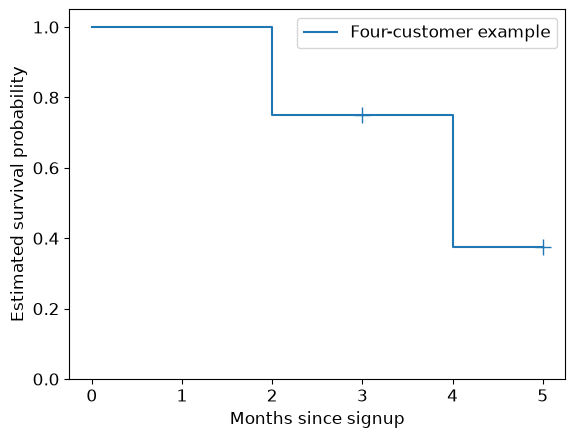

In [6]:
small = pd.DataFrame({"duration": [2, 3, 4, 5], "event": [1, 0, 1, 0]})
small_km = KaplanMeierFitter(label="Four-customer example")
small_km.fit(small["duration"], event_observed=small["event"])
ax = small_km.plot_survival_function(ci_show=False, show_censors=True)
ax.set(xlabel="Months since signup", ylabel="Estimated survival probability", ylim=(0, 1.05))
plt.show()

After month 5, nobody remains under observation. A flat tail does not establish that remaining customers will never churn; we have run out of follow-up.

### Kaplan–Meier for the telecom data

We can now fit the same estimator to the training data. It uses only duration and event status, without any other customer features.

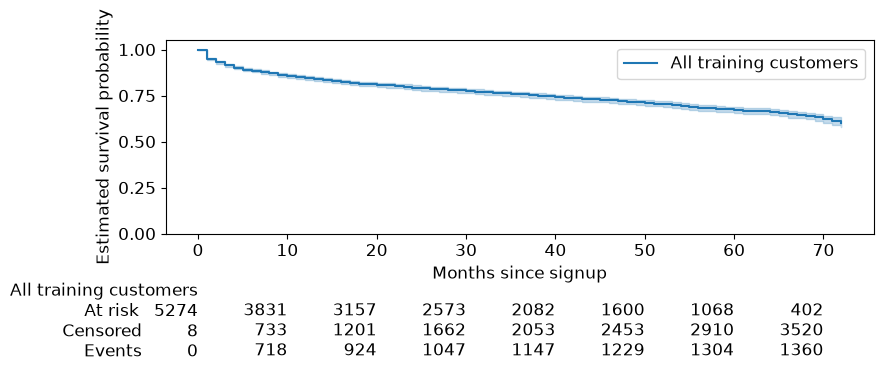

12    0.845665
24    0.793375
48    0.716790
Name: Estimated probability of staying beyond t, dtype: float64

In [7]:
kmf = KaplanMeierFitter(label="All training customers")
kmf.fit(train_df["tenure"], event_observed=train_df["event_observed"])
fig, ax = plt.subplots(figsize=(9, 4))
kmf.plot_survival_function(ax=ax)
ax.set(xlabel="Months since signup", ylabel="Estimated survival probability", ylim=(0, 1.05))
add_at_risk_counts(kmf, ax=ax)
plt.tight_layout()
plt.show()
display(kmf.predict([12, 24, 48]).rename("Estimated probability of staying beyond t"))

The curve falls at observed churn times. The shaded region gives pointwise 95% confidence intervals for the estimated population survival probability; it is not a range of individual churn times. The counts below the plot help us see how much follow-up supports the curve. Far into the tail, fewer customers remain under observation, so estimates deserve particular caution.

The ordinary mean of `tenure` would mix completed subscriptions with incomplete follow-up. It is not the mean time to churn. A survival curve is more informative here, but it also cannot identify what happens beyond the available follow-up without additional assumptions.

We can also compare curves for groups. For example, do the observed survival patterns differ for senior and non-senior customers?

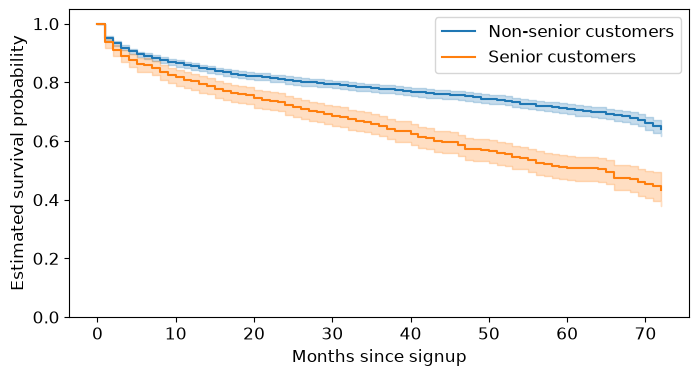

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for value, label in [(0, "Non-senior customers"), (1, "Senior customers")]:
    group = train_df.loc[train_df["SeniorCitizen"].eq(value)]
    group_km = KaplanMeierFitter(label=label)
    group_km.fit(group["tenure"], event_observed=group["event_observed"])
    group_km.plot_survival_function(ax=ax)
ax.set(xlabel="Months since signup", ylabel="Estimated survival probability", ylim=(0, 1.05))
plt.show()

These are unadjusted comparisons. The groups may also differ in contracts, services, and other attributes. A difference between curves does not establish that senior status causes a difference in churn.

### Exercise 20.2: Read the curve

Return to the four-customer example.

1. Why does the curve stay flat at month 3 even though one customer leaves observation?
2. If B had instead churned at month 3, what would the survival estimate be immediately after month 3?
3. Why would dividing the number known to remain subscribed by all four original customers give the wrong estimate after month 4?

## Using features: the Cox proportional hazards model

The subgroup curves suggest that survival patterns differ across customers. But comparing one grouping at a time leaves other differences mixed together. Senior and non-senior customers, for example, may also have different contracts. How can we use several features together?

We need a regression model designed for survival outcomes. The **Cox proportional hazards model** keeps the duration/event representation we have just used and adds customer features. It lets us estimate associations while holding the other included features fixed, and produce a survival curve for a particular feature profile.

First we need to distinguish **survival** from **hazard**. Survival is the probability of remaining event-free beyond a time. Hazard describes the rate at which events occur around that time among individuals who have remained event-free until then. A higher churn hazard means a faster rate of churn among customers still subscribed. A hazard is a rate, not a probability.

The Cox model assigns a coefficient to each feature. Rather than adding a fixed number of months to a prediction, a feature change multiplies the hazard. A one-unit increase in a feature with coefficient $\beta$, holding the other features fixed, multiplies hazard by $\exp(\beta)$. This multiplier is the **hazard ratio**.

| Coefficient | Hazard ratio | Interpretation, holding other features fixed |
|---|---|---|
| $0$ | $1$ | No change in hazard |
| $\log(2)$ | $2$ | Twice the hazard |
| $\log(0.5)$ | $0.5$ | Half the hazard |

Twice the hazard does not mean twice the probability of churn within 12 months, nor half the expected lifetime.

The **proportional hazards assumption** is that this hazard ratio stays constant over time. The overall churn rate can rise or fall, but the model assumes a feature's multiplicative effect does not change with duration. A contract that reduces churn early but increases it around renewal could violate this assumption.

### Preparing the features

We use the same small feature set as in the regression demonstration. We omit `customerID`, which is an identifier, and `TotalCharges`, which accumulates during the subscription and can reveal information about elapsed time. We also leave `tenure` and `event_observed` out of the predictors: together, they describe the outcome.

We retain monthly charges in dollars so that changes in this feature remain easy to interpret. We one-hot encode categories with a reference category (`drop="first"`). Each retained category is compared with the omitted category for that feature. We fit the encoder on training data only.

In [9]:
survival_preprocessor = ColumnTransformer(
    [
        ("numeric", "passthrough", numeric_features),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore",
                                      sparse_output=False), categorical_features),
        ("binary", "passthrough", ["SeniorCitizen"]),
    ],
    verbose_feature_names_out=False,
)
survival_preprocessor.fit(train_df[feature_columns])
encoded_columns = survival_preprocessor.get_feature_names_out()

def survival_frame(frame):
    encoded = pd.DataFrame(
        survival_preprocessor.transform(frame[feature_columns]),
        index=frame.index, columns=encoded_columns,
    )
    return encoded.join(frame[["tenure", "event_observed"]])

train_surv = survival_frame(train_df)
test_surv = survival_frame(test_df)
encoder = survival_preprocessor.named_transformers_["categorical"]
display(pd.Series({name: categories[0] for name, categories in
                   zip(categorical_features, encoder.categories_)}, name="Reference category"))
display(train_surv.head())

Contract                      Month-to-month
InternetService                          DSL
PaymentMethod      Bank transfer (automatic)
Name: Reference category, dtype: object

,MonthlyCharges,Contract_One year,Contract_Two year,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen,tenure,event_observed
6464,70.35,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,50,0
5707,45.55,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2,0
3442,98.80,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,29,0
3932,78.55,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,2,1
6124,59.30,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,57,0


### Fitting and interpreting the model

Unlike a scikit-learn regressor, `lifelines` accepts a single DataFrame containing features and both outcome columns. We tell it which columns are duration and event status.

We add a small L2 penalty to stabilize coefficient estimates, similar in spirit to `Ridge`. With the default `l1_ratio=0`, `penalizer=0.1` uses L2 regularization. This is a fixed teaching choice, not a value selected using the test set. Regularization does not repair inappropriate features or a violation of proportional hazards.

In [10]:
cph = CoxPHFitter(penalizer=0.1)
cph.fit(train_surv, duration_col="tenure", event_col="event_observed")
display(cph.summary[["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%"]])

,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%
covariate,,,,
MonthlyCharges,-0.005730,0.994287,0.992168,0.996410
Contract_One year,-1.034271,0.355486,0.314173,0.402230
Contract_Two year,-1.502138,0.222654,0.194800,0.254490
InternetService_Fiber optic,0.505673,1.658101,1.477467,1.860819
InternetService_No,-0.448655,0.638486,0.547884,0.744071
PaymentMethod_Credit card (automatic),-0.248840,0.779705,0.682731,0.890453
PaymentMethod_Electronic check,0.513960,1.671899,1.504854,1.857487
PaymentMethod_Mailed check,0.305656,1.357515,1.188641,1.550381
SeniorCitizen,0.052152,1.053536,0.942953,1.177088


Positive coefficients are associated with higher hazard and lower survival; negative coefficients are associated with lower hazard and higher survival, holding the included features fixed. For example, a contract coefficient compares that contract with the reference contract, rather than comparing customers with and without any contract.

For monthly charges, a one-dollar change may be too small to interpret conveniently. The hazard ratio for a $10 increase is $\exp(10\beta)$, because the feature remains in dollars.

Hazard ratio for a $10 increase in monthly charges: 0.944


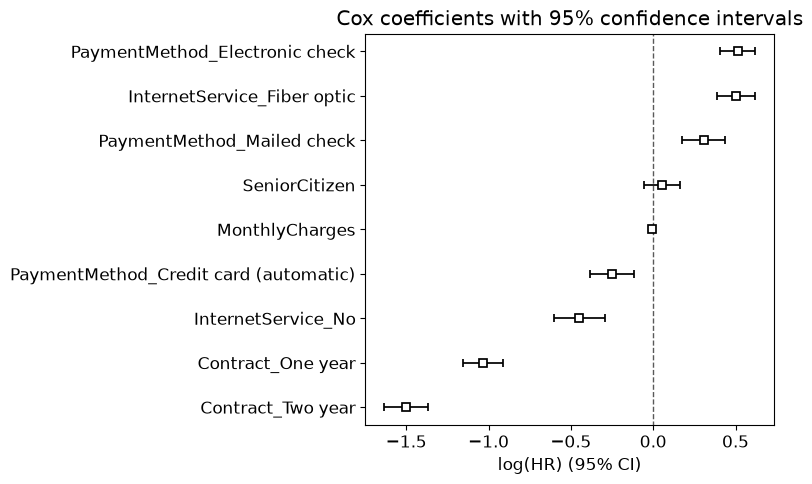

In [11]:
charge_hazard_ratio = np.exp(10 * cph.params_["MonthlyCharges"])
print(f"Hazard ratio for a $10 increase in monthly charges: {charge_hazard_ratio:.3f}")
fig, ax = plt.subplots(figsize=(8, 5))
cph.plot(ax=ax)
ax.set_title("Cox coefficients with 95% confidence intervals")
plt.tight_layout()
plt.show()

The intervals describe uncertainty under the model and its assumptions. They do not establish causal effects. In particular, an association between contract type and churn does not show what would happen if we changed a customer's contract.

For a real analysis, we would inspect model diagnostics as well. `cph.check_assumptions(train_surv)` provides checks and plots for proportional hazards; interpreting them and choosing a remedy requires more statistical detail than we cover here. A model that converges successfully is not necessarily an adequate model.

## Making and evaluating predictions

Return to the retention team’s question: when might a customer leave? The fitted coefficients describe associations, but the team needs predictions for particular customers. A survival curve lets us ask about a relevant horizon, such as the probability of staying beyond 12 months, without reducing the whole outlook to one event time.

### Predictions from signup

First, consider curves measured from **signup**. We use held-out customers' features, excluding the duration and event indicator. These are model illustrations under our fixed-feature interpretation, subject to the snapshot limitations described earlier.

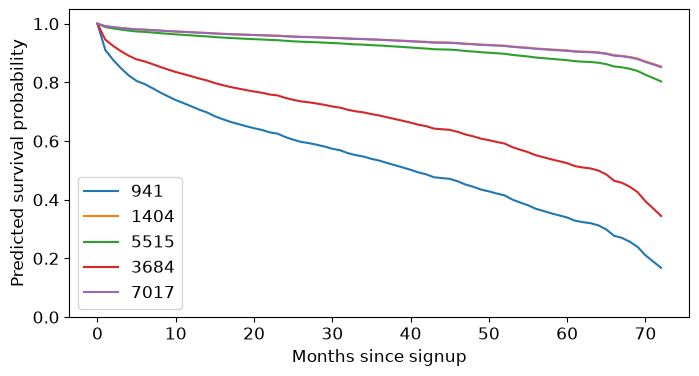

,P(stay beyond 12 months),P(stay beyond 24 months)
941,0.718279,0.613673
1404,0.971162,0.957738
5515,0.960181,0.941801
3684,0.820788,0.747195
7017,0.970727,0.957105


In [12]:
test_X = test_surv.drop(columns=["tenure", "event_observed"])
example_X = test_X.head(5)
survival_predictions = cph.predict_survival_function(example_X, times=np.arange(0, 73))
ax = survival_predictions.plot(figsize=(8, 4))
ax.set(xlabel="Months since signup", ylabel="Predicted survival probability", ylim=(0, 1.05))
plt.show()
display(cph.predict_survival_function(example_X, times=[12, 24]).T.rename(
    columns={12.0: "P(stay beyond 12 months)", 24.0: "P(stay beyond 24 months)"}
))

Each curve starts at the model's time origin, signup. It is not automatically a forecast of months from today for an existing customer.

We can also vary one feature while holding the rest fixed. Here we use the training-set quartiles of monthly charges, so the inputs are plausible dollar amounts. This plot describes the fitted model's response; changing a price in practice need not have the same effect.

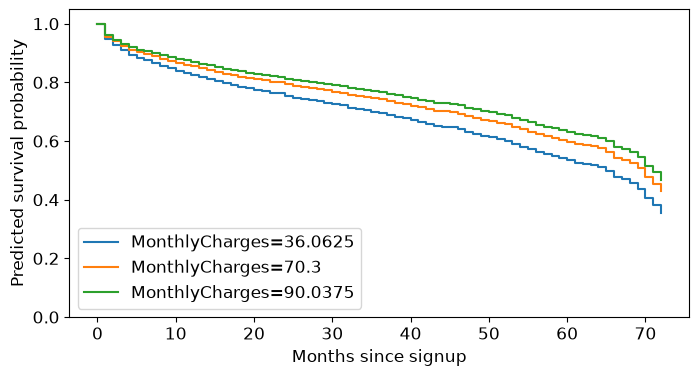

In [13]:
charge_values = train_df["MonthlyCharges"].quantile([0.25, 0.5, 0.75]).tolist()
cph.plot_partial_effects_on_outcome("MonthlyCharges", values=charge_values,
                                    plot_baseline=False, figsize=(8, 4))
plt.xlabel("Months since signup")
plt.ylabel("Predicted survival probability")
plt.ylim(0, 1.05)
plt.show()

### The outlook for an existing customer

For retention planning, however, we usually want the outlook for someone who is already subscribed. Suppose a customer has already stayed for 20 months. A prediction from signup includes the possibility of leaving before month 20, but we now know that did not happen. We should **condition on their survival so far**.

For a customer who has survived to month $a$, the probability of staying for more than another $u$ months is

$$\frac{S(a+u)}{S(a)},$$

provided $S(a)>0$. We keep only the survival beyond month $a$ and rescale that part of the curve to begin at 1. `lifelines` does this through `conditional_after`.

Let's select active held-out customers with at most 48 months of observed tenure, so that a further 12 months remains within the dataset's duration range.

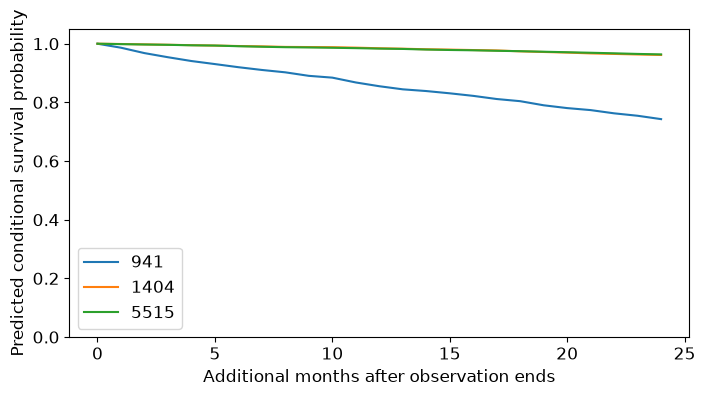

,Months already subscribed,P(stay another 12 months)
941,13,0.855102
1404,35,0.984491
5515,18,0.983319


In [14]:
active = test_surv.loc[
    test_surv["event_observed"].eq(0) & test_surv["tenure"].le(48)
].head(3)
active_X = active.drop(columns=["tenure", "event_observed"])
remaining_survival = cph.predict_survival_function(
    active_X, times=np.arange(0, 25), conditional_after=active["tenure"].to_numpy()
)
ax = remaining_survival.plot(figsize=(8, 4))
ax.set(xlabel="Additional months after observation ends",
       ylabel="Predicted conditional survival probability", ylim=(0, 1.05))
plt.show()
display(pd.DataFrame({
    "Months already subscribed": active["tenure"],
    "P(stay another 12 months)": remaining_survival.loc[12],
}))

These are predictions of remaining survival, given each customer's observed tenure. Conditioning on survival does not guarantee a longer expected *remaining* lifetime than for a new customer; that depends on the fitted survival pattern.

`lifelines` can also return medians and expected lifetimes. These summaries require care. A median may be unavailable if the curve never falls to 0.5 during follow-up. An expected lifetime depends on the entire tail, including durations we may not have observed. We therefore begin with probabilities at supported horizons rather than treating a single predicted lifetime as a precise answer.

### Exercise 20.3: Which prediction answers the question?

A customer has already stayed for 20 months. A model gives $S(20)=0.8$ and $S(32)=0.6$ for their features.

1. What is their predicted probability of remaining subscribed for another 12 months, given survival to month 20?
2. Why is $1-S(12)$ not the appropriate predicted probability of churn during their next 12 months?
3. If two customers have identical model features but different observed tenures, must their remaining-survival curves be identical? Explain.

### Evaluating a survival model

We can now produce predictions that answer our original question. Before using them, we need to check how well the model performs on customers it did not train on. The incomplete-target problem that motivated survival analysis also affects evaluation.

Ordinary mean squared error cannot directly compare a predicted event time with every row's observed tenure. For a censored customer, tenure is a bound, not the true event time. Evaluating only observed events would again select an unrepresentative subset.

One common survival metric is the **concordance index**, or **c-index**. It asks whether the model correctly ranks risk for pairs of individuals whose event order can be determined. If A churns at month 4 and B is observed event-free through month 10, we know A's event occurred first. If A is censored at month 4 and B churns at month 10, we do not know which customer's event time is earlier, so that pair cannot be ordered in the same way.

A c-index of 1 indicates perfect ordering of comparable pairs; around 0.5 corresponds to chance ordering. This measures ranking, not whether predicted survival probabilities are accurate. A model can rank customers well while systematically overestimating survival.

We now evaluate our fixed model once on the test set. We also show the training score to distinguish performance on seen and unseen customers.

In [15]:
scores = pd.Series({
    "Training c-index": cph.score(train_surv, scoring_method="concordance_index"),
    "Test c-index": cph.score(test_surv, scoring_method="concordance_index"),
})
display(scores.round(3))

Training c-index    0.824
Test c-index        0.821
dtype: float64

This random split estimates generalization to customers sampled in a similar way to this snapshot. A deployment on future signup cohorts would call for a time-based evaluation, with features recorded at the intended prediction time. We would also assess whether probabilities match observed survival at relevant horizons, using evaluation methods that account for censoring. The c-index alone cannot establish that the model is ready for retention decisions.

## Practical guidance and limitations

We began with a familiar choice between classification and regression, then found that neither ordinary workflow preserved the information in our targets. The useful first question was not which algorithm to fit, but what we knew about each customer’s event time. That same question guides the choice of approach in other applications.

Use survival analysis when the question concerns time until an event and some event times are only partly observed. Kaplan–Meier is a useful starting point for describing a population or comparing unadjusted group curves. Cox regression incorporates multiple features, with interpretable hazard ratios under the proportional hazards assumption.

If the goal is a single fixed-horizon decision and everyone has sufficient follow-up for that horizon, ordinary classification may be simpler. If all event times are observed exactly, ordinary regression may be reasonable, although time-to-event models can still be useful. The choice follows from the question and the observation process, rather than from the presence of a time column alone.

Other survival methods include random survival forests and models that allow feature effects to change with time. Some problems also require features that change during follow-up, such as a customer switching plans. These require a richer data representation than one snapshot row per customer.

We have focused on right censoring. With **left censoring**, an event is known to have happened before a bound, but its exact time is unknown. With **interval censoring**, it is known to have occurred between two observation times. These differ from a record that simply begins late; defining what was observed is essential before choosing a method.

## Summary

- **Right-censored outcomes contain partial information.** We know that the event time exceeds the observed duration. Dropping these records loses information; treating their durations as completed lifetimes gives ordinary regression the wrong targets.
- **Represent the outcome with duration and event status.** The event indicator distinguishes an observed event from the end of follow-up. A censored record does not mean the event will never happen.
- **Use survival curves to describe time to an event.** The survival function gives the probability of remaining event-free beyond a given time. Kaplan–Meier estimates a population curve, with censored individuals contributing while they remain under observation.
- **Use Cox regression to incorporate features.** Its coefficients describe multiplicative changes in hazard, holding other included features fixed. The proportional hazards assumption keeps these hazard ratios constant over time; they are associations, not causal effects.
- **Distinguish total from remaining survival.** A curve measured from signup differs from the outlook for an existing customer. For that customer, condition on survival through their observed tenure.
- **Evaluate with methods that respect censoring.** The c-index measures risk ranking among comparable pairs, not the accuracy of predicted survival probabilities. Use held-out data and check performance at horizons relevant to the intended decision.

For a new problem, define the event, time origin, and prediction time before choosing a model. Check which features were available then, why observations were censored, and whether the model's assumptions are reasonable.

**Further reading**

- [Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).
- [Kaplan–Meier estimation in lifelines](https://lifelines.readthedocs.io/en/latest/Survival%20analysis%20with%20lifelines.html).
- [Survival regression, interpretation, and diagnostics](https://lifelines.readthedocs.io/en/latest/Survival%20Regression.html).
- [CoxPHFitter API, including conditional predictions and prediction limitations](https://lifelines.readthedocs.io/en/latest/fitters/regression/CoxPHFitter.html).